# 05 – Electorate-level analysis
One row per electorate, party vote only, **ordinary votes** (`advance` + `election_day`) so 2026 (preliminary)
and 2023 are like-for-like. Needs notebook 01 and 02 only: no geocoding.

2023 → 2026 change is shown for every electorate, matched by name. The 10 seats renamed in the 2025 boundary review
are matched to their main 2023 predecessor (Commission's list, `electorates.PREDECESSOR`). Many seats were also
redrawn: the `overlap` column says how much of the 2026 seat came from the 2023 seat it is compared with
(100 = same area), so treat swings in low-overlap seats with care.
Change `FOCUS` to look at any party.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import places

FOCUS = "Green Party"
TOP_N = 15             # rows in the ranking charts
HEATMAP_PARTIES = 8    # biggest parties nationally in 2026
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)

pv = pd.read_parquet(ROOT / "data/staging/stg_party_votes.parquet")
pv = pv[pv.place_kind.isin(places.ORDINARY)]
rel = pd.read_csv(ROOT / "data/reference/electorate_relationships_2026.csv")
# Electorates are compared by name, using the Commission's list of 2025 name changes for the 10 renamed seats
# (`electorates.PREDECESSOR`, e.g. East Coast -> East Cape). The boundary review moved some of them, so `overlap`
# (share of the 2026 seat's votes from the 2023 seat it is compared with, notebook 02) is shown as a caveat.
import electorates
pv = electorates.align_2023(pv)
names = pv.groupby("election_year").electorate.agg(set)
comparable = names[2023] & names[2026]
roll = rel.set_index("electorate_2026").roll
overlap = electorates.seat_overlap()

## 1. Party share by electorate and year

In [2]:
t = pv.groupby(["election_year", "electorate", "party"], as_index=False)["votes"].sum()
t["valid"] = t.groupby(["election_year", "electorate"]).votes.transform("sum")
t["share"] = t.votes / t.valid * 100
share = t.pivot_table(index=["electorate", "party"], columns="election_year", values="share")
share["swing_pts"] = share[2026] - share[2023]
share.loc[~share.index.get_level_values("electorate").isin(comparable), "swing_pts"] = np.nan
print(f"{len(comparable)} of {len(rel)} electorates compared across years (by name, renames via the Commission list)")

57 comparable electorates of 71


## 2. Where is `FOCUS` strongest in 2026?

election_year,electorate,2023,2026,swing_pts,roll,comparable
65,Waiariki,5.5,38.0,32.5,maori,True
60,Te Tai Tonga,16.5,37.3,20.9,maori,True
58,Te Tai Hauāuru,7.8,37.2,29.5,maori,True
59,Te Tai Tokerau,9.2,36.7,27.5,maori,True
63,Tāmaki Makaurau,12.3,35.6,23.3,maori,True
15,Hauraki-Waikato,7.2,34.4,27.2,maori,True
18,Ikaroa-Rāwhiti,6.7,32.2,25.5,maori,True
71,Wellington Bays,NaN,29.0,NaN,general,False
73,Wellington North,NaN,27.1,NaN,general,False
7,Dunedin,26.2,26.1,-0.1,general,True


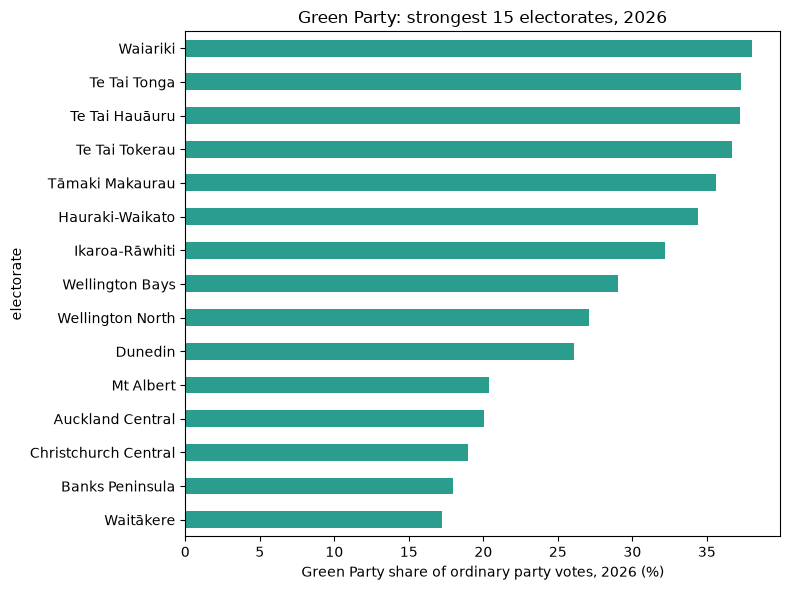

In [3]:
f = share.xs(FOCUS, level="party").reset_index()
f["roll"] = f.electorate.map(roll)
f["comparable"] = f.electorate.isin(comparable)
f["overlap"] = f.electorate.map(overlap)
top = f.sort_values(2026, ascending=False).head(TOP_N)
display(top.round(1))
ax = top.set_index("electorate")[2026].iloc[::-1].plot.barh(figsize=(8, 6), color="#2a9d8f")
ax.set_xlabel(f"{FOCUS} share of ordinary party votes, 2026 (%)")
ax.set_title(f"{FOCUS}: strongest {TOP_N} electorates, 2026")
plt.tight_layout(); plt.show()

## 3. Change since 2023 (comparable electorates)

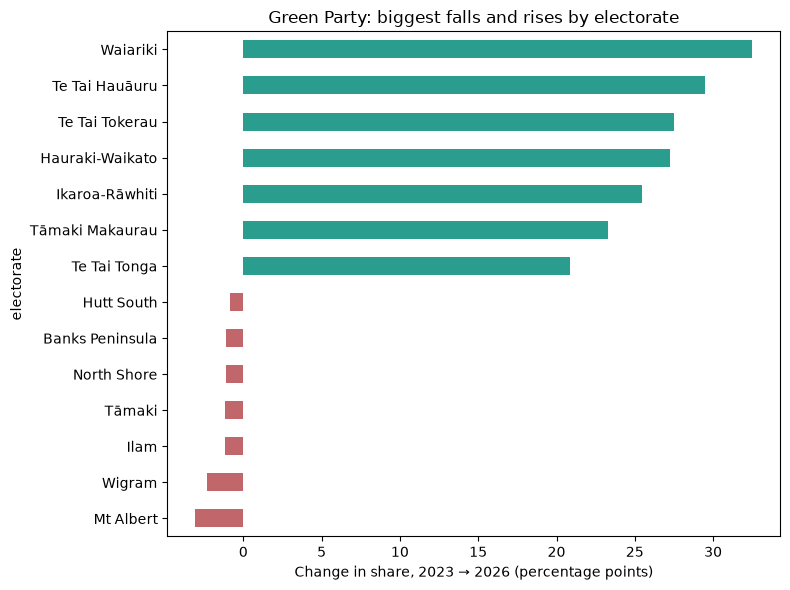

election_year,electorate,roll,2023,2026,swing_pts
18,Ikaroa-Rāwhiti,maori,6.7,32.2,25.5
15,Hauraki-Waikato,maori,7.2,34.4,27.2
59,Te Tai Tokerau,maori,9.2,36.7,27.5
58,Te Tai Hauāuru,maori,7.8,37.2,29.5
65,Waiariki,maori,5.5,38.0,32.5


In [4]:
sw = f[f.comparable].dropna(subset=["swing_pts"]).sort_values("swing_pts")
ends = pd.concat([sw.head(TOP_N // 2), sw.tail(TOP_N // 2)])
ax = ends.set_index("electorate")["swing_pts"].plot.barh(figsize=(8, 6), color=np.where(ends.swing_pts > 0, "#2a9d8f", "#c1666b"))
ax.set_xlabel("Change in share, 2023 → 2026 (percentage points)")
ax.set_title(f"{FOCUS}: biggest falls and rises by electorate")
plt.tight_layout(); plt.show()
display(sw[["electorate", "roll", 2023, 2026, "swing_pts"]].round(1).tail(5))

## 4. Leading party in each electorate (party vote)
`flipped` marks comparable electorates where a different party led in 2023.

In [5]:
lead = t.sort_values("votes", ascending=False).drop_duplicates(["election_year", "electorate"])
lead = lead.pivot(index="electorate", columns="election_year", values="party").rename(columns={2023: "lead_2023", 2026: "lead_2026"})
margin = (t.sort_values("share", ascending=False).groupby(["election_year", "electorate"]).share
          .apply(lambda s: s.iloc[0] - s.iloc[1]).unstack(level=0).rename(columns={2023: "margin_2023", 2026: "margin_2026"}))
lead = lead.join(margin)
lead.loc[~lead.index.isin(comparable), ["lead_2023", "margin_2023"]] = np.nan
lead["flipped"] = lead.lead_2023.notna() & (lead.lead_2023 != lead.lead_2026)
print("Electorates led by each party in 2026:")
display(lead.lead_2026.value_counts().to_frame("electorates"))
display(lead[lead.flipped].round(1))
display(lead.sort_values("margin_2026").head(10).round(1))   # closest contests for the party vote

Electorates led by each party in 2026:


,electorates
lead_2026,
National Party,40
Labour Party,31


election_year,lead_2023,lead_2026,margin_2023,margin_2026,flipped
electorate,,,,,
Banks Peninsula,National Party,Labour Party,4.9,1.8,True
Christchurch Central,National Party,Labour Party,2.0,8.6,True
Hamilton West,National Party,Labour Party,14.3,3.0,True
Hutt South,National Party,Labour Party,1.8,11.7,True
Maungakiekie,National Party,Labour Party,15.3,1.8,True
Mt Albert,National Party,Labour Party,5.9,6.0,True
Nelson,National Party,Labour Party,3.3,1.8,True
Palmerston North,National Party,Labour Party,2.9,5.9,True
Wigram,National Party,Labour Party,4.6,4.5,True


election_year,lead_2023,lead_2026,margin_2023,margin_2026,flipped
electorate,,,,,
Takanini,National Party,National Party,26.9,0.5,False
Auckland Central,NaN,National Party,NaN,0.9,False
Mt Roskill,NaN,Labour Party,NaN,1.8,False
Maungakiekie,National Party,Labour Party,15.3,1.8,True
Nelson,National Party,Labour Party,3.3,1.8,True
Hamilton East,National Party,National Party,18.7,1.8,False
Banks Peninsula,National Party,Labour Party,4.9,1.8,True
East Cape,NaN,National Party,NaN,2.1,False
Wairarapa,National Party,National Party,11.9,2.2,False


## 4b. Seat winners (candidate vote) vs party-vote leaders, 2026
Electorate seats go to the candidate with most **candidate** votes, which is not always the party with most
**party** votes. This reproduces the Commission's projected electorate seats (National 42, Labour 21, Green 2, ACT 1,
Te Pāti Māori 5); the same check runs in `tests/official_results/test_2026_national.py`.
The candidate → party link for winners is in `data/reference/ge2026_winner_parties.csv`.

In [ ]:
import electorates

cv = pd.read_parquet(ROOT / "data/staging/stg_candidate_votes.parquet")
win = electorates.winners_2026(cv).set_index("electorate")
win["party_vote_leader"] = lead.lead_2026
win["differs"] = win.party != win.party_vote_leader
display(win.party.value_counts().to_frame("seats won"))
print(f"{win.differs.sum()} of {len(win)} seats were won by a different party than led the party vote:")
display(win[win.differs][["candidate", "party", "party_vote_leader", "margin"]])
print("Narrowest seat margins (ordinary votes only; special votes can still change these):")
display(win.sort_values("margin").head(8)[["candidate", "party", "margin"]])

## 5. The shape of each electorate: top parties, 2026

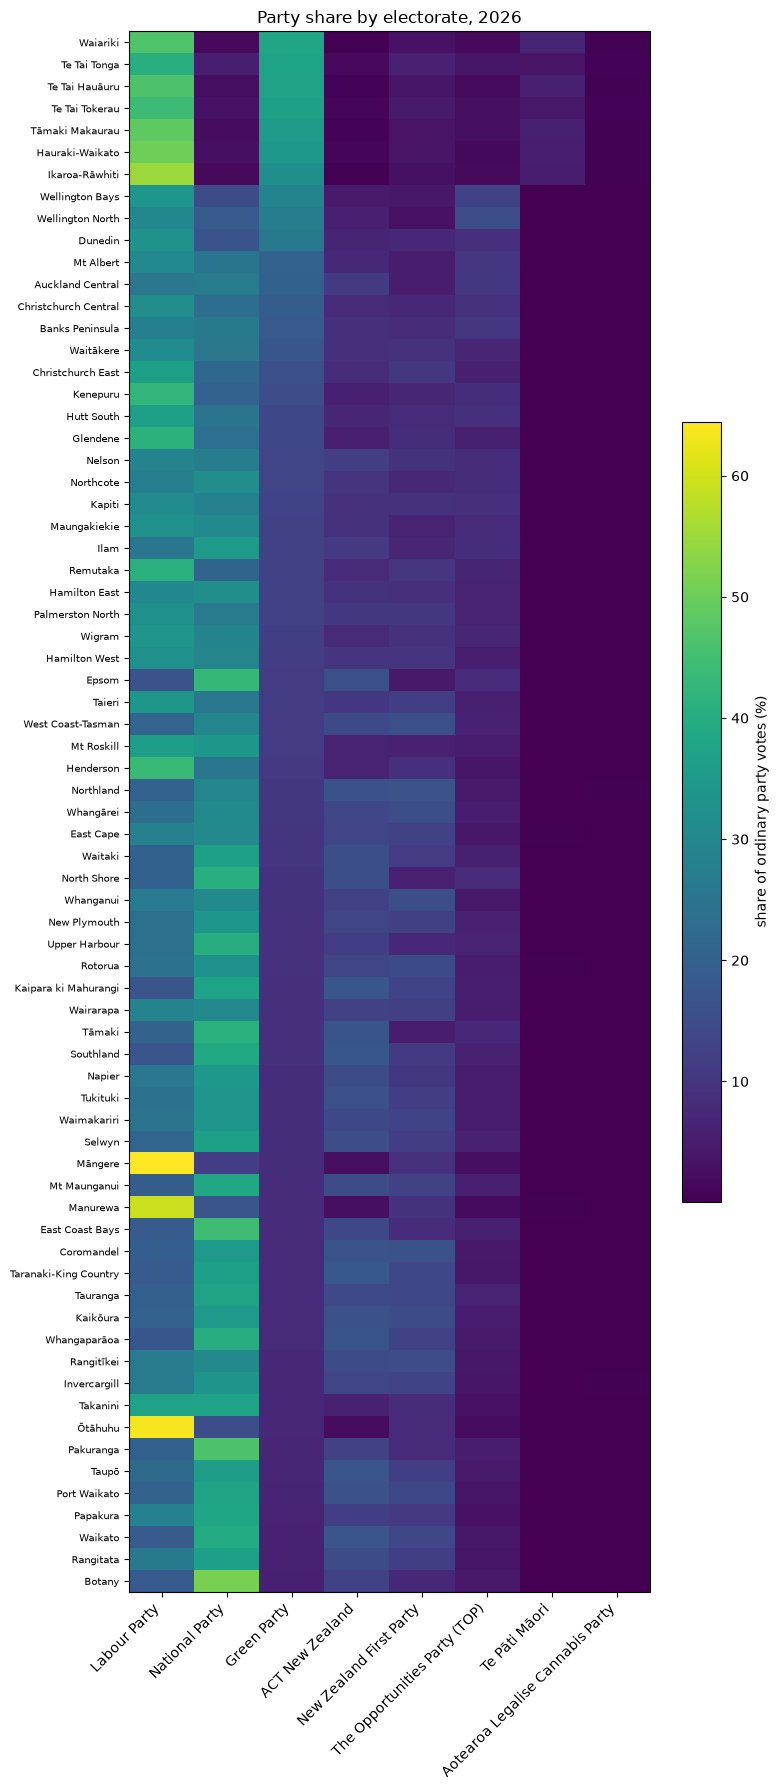

In [6]:
big = t[t.election_year == 2026].groupby("party").votes.sum().nlargest(HEATMAP_PARTIES).index
h = t[(t.election_year == 2026) & t.party.isin(big)].pivot(index="electorate", columns="party", values="share")[list(big)]
h = h.sort_values(FOCUS if FOCUS in h else big[0], ascending=False)
fig, ax = plt.subplots(figsize=(8, 18))
im = ax.imshow(h.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(h.columns)), h.columns, rotation=45, ha="right")
ax.set_yticks(range(len(h)), h.index, fontsize=7)
fig.colorbar(im, label="share of ordinary party votes (%)", shrink=0.5)
ax.set_title("Party share by electorate, 2026")
plt.tight_layout(); plt.show()

## 6. How many ordinary votes (comparable electorates)
Ordinary votes only, so this is a rough guide to turnout, not turnout itself: 2026 has no special votes yet.

In [7]:
v = t.groupby(["election_year", "electorate"]).valid.first().unstack(level=0)
v = v[v.index.isin(comparable)].dropna()
v["change_pct"] = (v[2026] / v[2023] - 1) * 100
display(v.sort_values("change_pct").round(1).head(5)); display(v.sort_values("change_pct").round(1).tail(5))

election_year,2023,2026,change_pct
electorate,,,
Takanini,27796.0,25432.0,-8.5
Papakura,30947.0,28329.0,-8.5
Whangaparāoa,37350.0,35901.0,-3.9
Northland,38050.0,36600.0,-3.8
Kaipara ki Mahurangi,38808.0,37792.0,-2.6


election_year,2023,2026,change_pct
electorate,,,
Te Tai Hauāuru,19010.0,26296.0,38.3
Waiariki,20613.0,28659.0,39.0
Tāmaki Makaurau,17954.0,24993.0,39.2
Ikaroa-Rāwhiti,19324.0,27509.0,42.4
Hauraki-Waikato,17479.0,25952.0,48.5


## 7. Save the full table
One row per electorate × party, ready to open in a spreadsheet.

In [8]:
out = share.reset_index().rename(columns={2023: "share_2023", 2026: "share_2026"})
out["roll"] = out.electorate.map(roll)
out["comparable"] = out.electorate.isin(comparable)
out.round(3).to_csv(ROOT / "data/staging/electorate_party_share.csv", index=False)
print(f"{len(out)} rows -> data/staging/electorate_party_share.csv")

1699 rows -> data/staging/electorate_party_share.csv
